# ML evaluation plots

This notebook reads the checked-in `ml/artifacts/evaluation_report.json` and `ml/artifacts/training_history.json` files. The confusion matrix is oriented with true labels on rows and predicted labels on columns. No model is retrained and the source artifacts are read only.

In [9]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def find_artifact(name):
    """Find an artifact whether the notebook runs from the repo root or ml/."""
    candidates = [
        Path.cwd() / "ml" / "artifacts" / name,
        Path.cwd() / "artifacts" / name,
        Path(__file__).resolve().parent / "artifacts" / name,
    ] if "__file__" in globals() else [
        Path.cwd() / "ml" / "artifacts" / name,
        Path.cwd() / "artifacts" / name,
    ]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f"Could not find {name}; checked: {candidates}")


evaluation_path = find_artifact("evaluation_report.json")
history_path = find_artifact("training_history.json")
with evaluation_path.open(encoding="utf-8") as file:
    evaluation_report = json.load(file)
with history_path.open(encoding="utf-8") as file:
    training_history = json.load(file)

print(f"Loaded {evaluation_path}")
print(f"Loaded {history_path}")

Loaded c:\Users\saich\Desktop\cyber-chowkidar\ml\artifacts\evaluation_report.json
Loaded c:\Users\saich\Desktop\cyber-chowkidar\ml\artifacts\training_history.json


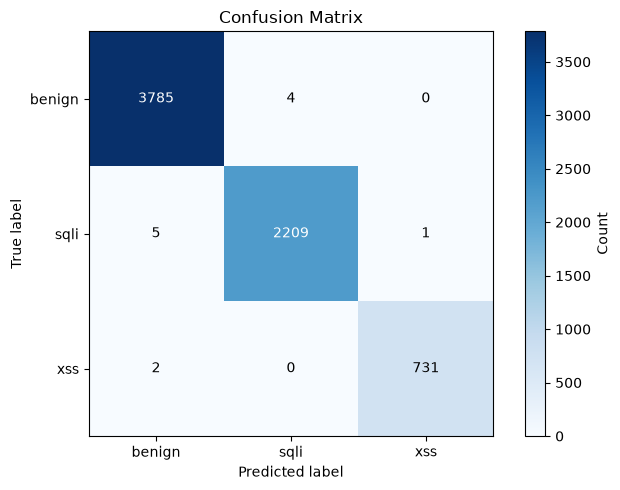

In [10]:
confusion = evaluation_report["confusion_matrix"]
labels = confusion["labels"]
matrix = np.asarray(confusion["matrix"])

fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(matrix, cmap="Blues")
ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticks(range(len(labels)), labels=labels)
ax.set_yticks(range(len(labels)), labels=labels)
fig.colorbar(image, ax=ax, label="Count")
threshold = matrix.max() / 2
for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        ax.text(column, row, matrix[row, column], ha="center", va="center",
                color="white" if matrix[row, column] > threshold else "black")
fig.tight_layout()
plt.show()

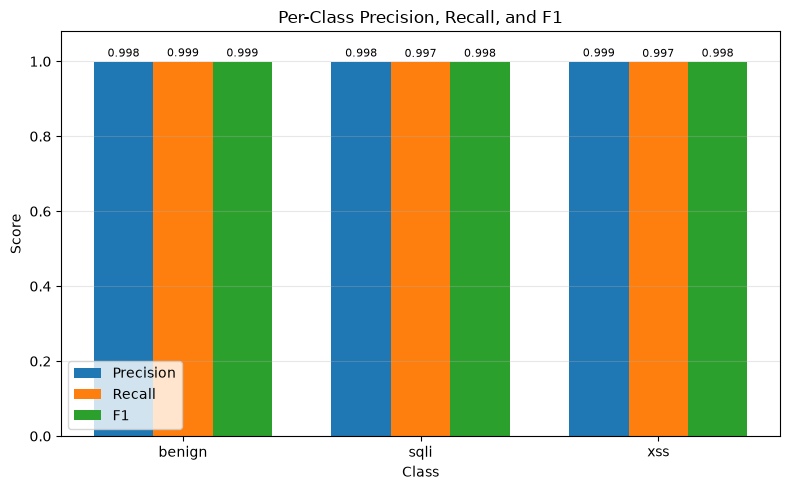

In [11]:
per_class = evaluation_report["per_class_metrics"]
metric_names = ["precision", "recall", "f1_score"]
metric_labels = ["Precision", "Recall", "F1"]
class_names = list(per_class)
x = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 5))
for offset, metric_name, metric_label in zip((-width, 0, width), metric_names, metric_labels):
    values = [per_class[class_name][metric_name] for class_name in class_names]
    bars = ax.bar(x + offset, values, width, label=metric_label)
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=8)
ax.set_title("Per-Class Precision, Recall, and F1")
ax.set_xlabel("Class")
ax.set_ylabel("Score")
ax.set_xticks(x, labels=class_names)
ax.set_ylim(0, 1.08)
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

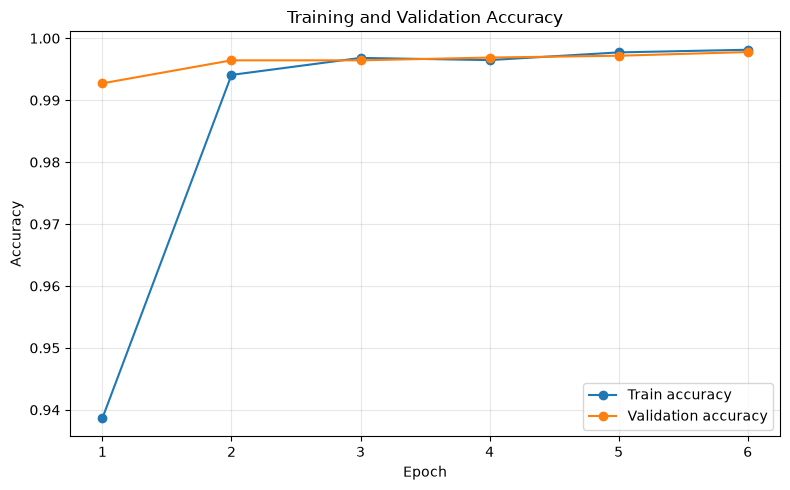

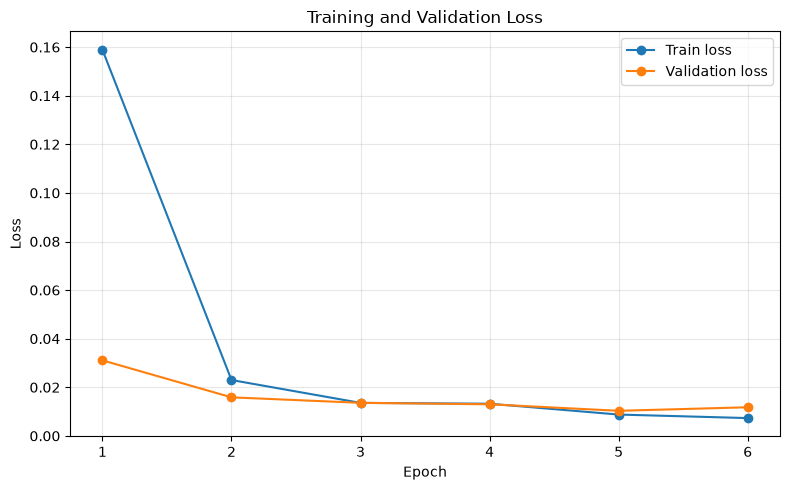

In [12]:
epochs = np.arange(1, training_history["epochs"] + 1)
train_acc = training_history["train_acc"]
val_acc = training_history["val_acc"]
train_loss = training_history["train_loss"]
val_loss = training_history["val_loss"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epochs, train_acc, marker="o", label="Train accuracy")
ax.plot(epochs, val_acc, marker="o", label="Validation accuracy")
ax.set_title("Training and Validation Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_xticks(epochs)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epochs, train_loss, marker="o", label="Train loss")
ax.plot(epochs, val_loss, marker="o", label="Validation loss")
ax.set_title("Training and Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_xticks(epochs)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()